# 1. Project Introduction
**Project Title:** Industrial Machine Failure Prediction  
**Program:** Learn Depth Academy LLP – Track 1 Final Capstone (Problem 21)  
**Domain:** Industrial Systems / Predictive Maintenance  
**Task:** Binary Classification  

Industrial predictive maintenance aims to identify early degradation indicators and anomalies in manufacturing machinery before functional failure occurs. This project implements a foundational machine-learning system to predict machine failure from operational sensor telemetry using the UCI AI4I 2020 Predictive Maintenance Dataset.

# 2. Problem Statement
Predict whether a milling machine is likely to experience an operational breakdown within a defined future operating window, utilizing non-invasive telemetry indicators while avoiding data leakage and addressing severe class imbalance.

# 3. Project Objective
Develop an end-to-end, zero-cost machine learning pipeline that:
1. Audits dataset quality and verifies absence of duplicates/missing entries.
2. Formulates domain-relevant features without synthetic fabrication.
3. Enforces strict data leakage prevention by excluding identifiers and post-failure flags.
4. Trains and rigorously benchmarks foundational classifiers (Logistic Regression, KNN, Decision Tree).
5. Prioritizes the minimization of False Negatives (unidentified breakdowns).
6. Persists the best pipeline and serves it via an interactive Streamlit application.

# 4. Dataset Description
- **Dataset:** AI4I 2020 Predictive Maintenance Dataset
- **Repository:** UCI Machine Learning Repository (DOI: 10.24432/C5HS5C)
- **Observations:** 10,000 milling machine operational records
- **Features:** 14 columns encompassing machine variant type, thermal measurements, spindle dynamics, wear indicators, and failure mode flags.

*Note on Capstone Expected Inputs vs Dataset:* The capstone generic template lists generic terms (Temperature, Vibration, Pressure, Runtime, Maintenance Gap). In this legitimate dataset, Temperature is provided directly (`Air temperature [K]`, `Process temperature [K]`), Vibration & Pressure correspond physically to spindle dynamic loads (`Torque [Nm]`, `Rotational speed [rpm]`), and Runtime/Maintenance gap is tracked via cumulative `Tool wear [min]`. No features are fabricated.

# 5. Import Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, roc_curve, auc
)

# Plotting configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 300, 'figure.figsize': (8, 5)})
print("Core libraries imported successfully.")

Core libraries imported successfully.


# 6. Load Dataset

In [2]:
# Path configuration
dataset_path = os.path.join('..', 'dataset', 'ai4i2020.csv')
if not os.path.exists(dataset_path):
    dataset_path = 'ai4i2020.csv'

df = pd.read_csv(dataset_path)
print(f"Dataset successfully loaded. Shape: {df.shape}")
df.head()

Dataset successfully loaded. Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


# 7. Dataset Overview

In [3]:
print("Dataset Information:")
df.info()

print("\nSummary Statistics of Continuous Numerical Features:")
df.describe()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3)

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


# 8. Data Quality Audit

In [4]:
print(f"Total Rows: {len(df)}")
print(f"Total Columns: {len(df.columns)}")
print(f"Constant Columns (nunique <= 1): {[col for col in df.columns if df[col].nunique() <= 1]}")
print(f"Categorical Columns: {df.select_dtypes(include=['object']).columns.tolist()}")
print(f"Numerical Columns: {df.select_dtypes(include=['int64', 'float64']).columns.tolist()}")

Total Rows: 10000
Total Columns: 14
Constant Columns (nunique <= 1): []
Categorical Columns: ['Product ID', 'Type']
Numerical Columns: ['UDI', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


C:\Users\VISHALRR\AppData\Local\Temp\ipykernel_13308\3540219374.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(f"Categorical Columns: {df.select_dtypes(include=['object']).columns.tolist()}")


# 9. Missing Value Analysis

In [5]:
missing = df.isnull().sum()
print("Missing values per column:")
print(missing)
print(f"\nTotal missing values across dataset: {missing.sum()}")
assert missing.sum() == 0, "Missing values detected!"
print("Verification: No missing values found in the dataset.")

Missing values per column:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Total missing values across dataset: 0
Verification: No missing values found in the dataset.


# 10. Duplicate Analysis

In [6]:
dup_count = df.duplicated().sum()
print(f"Number of duplicate records: {dup_count}")
print("Verification: All 10,000 records represent distinct operational measurements.")

Number of duplicate records: 0
Verification: All 10,000 records represent distinct operational measurements.


# 11. Target Distribution & Class Balance Analysis

Target Class Breakdown:
                 Count  Percentage (%)
Machine failure                       
0                 9661           96.61
1                  339            3.39


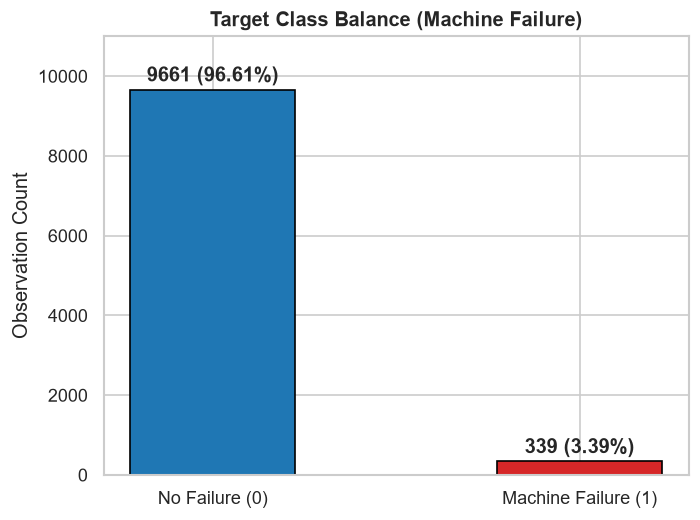

Imbalance Ratio: ~28.5 to 1.
Key Takeaway: Severe class imbalance necessitates evaluation metrics beyond Accuracy (Recall, F1-Score, ROC-AUC).


In [7]:
target_counts = df['Machine failure'].value_counts()
target_pct = df['Machine failure'].value_counts(normalize=True) * 100

print("Target Class Breakdown:")
print(pd.DataFrame({'Count': target_counts, 'Percentage (%)': target_pct}))

fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(['No Failure (0)', 'Machine Failure (1)'], target_counts.values, color=['#1f77b4', '#d62728'], edgecolor='black', width=0.45)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 100, f'{yval} ({yval/len(df)*100:.2f}%)', ha='center', va='bottom', fontweight='bold')
ax.set_title('Target Class Balance (Machine Failure)', fontsize=12, fontweight='bold')
ax.set_ylabel('Observation Count')
ax.set_ylim(0, 11000)
plt.tight_layout()
plt.show()

print(f"Imbalance Ratio: ~{target_counts[0]/target_counts[1]:.1f} to 1.")
print("Key Takeaway: Severe class imbalance necessitates evaluation metrics beyond Accuracy (Recall, F1-Score, ROC-AUC).")

# 12. Exploratory Data Analysis (EDA)

C:\Users\VISHALRR\AppData\Local\Temp\ipykernel_13308\180067148.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Type', order=['L', 'M', 'H'], ax=axes[5], palette='Blues_r')


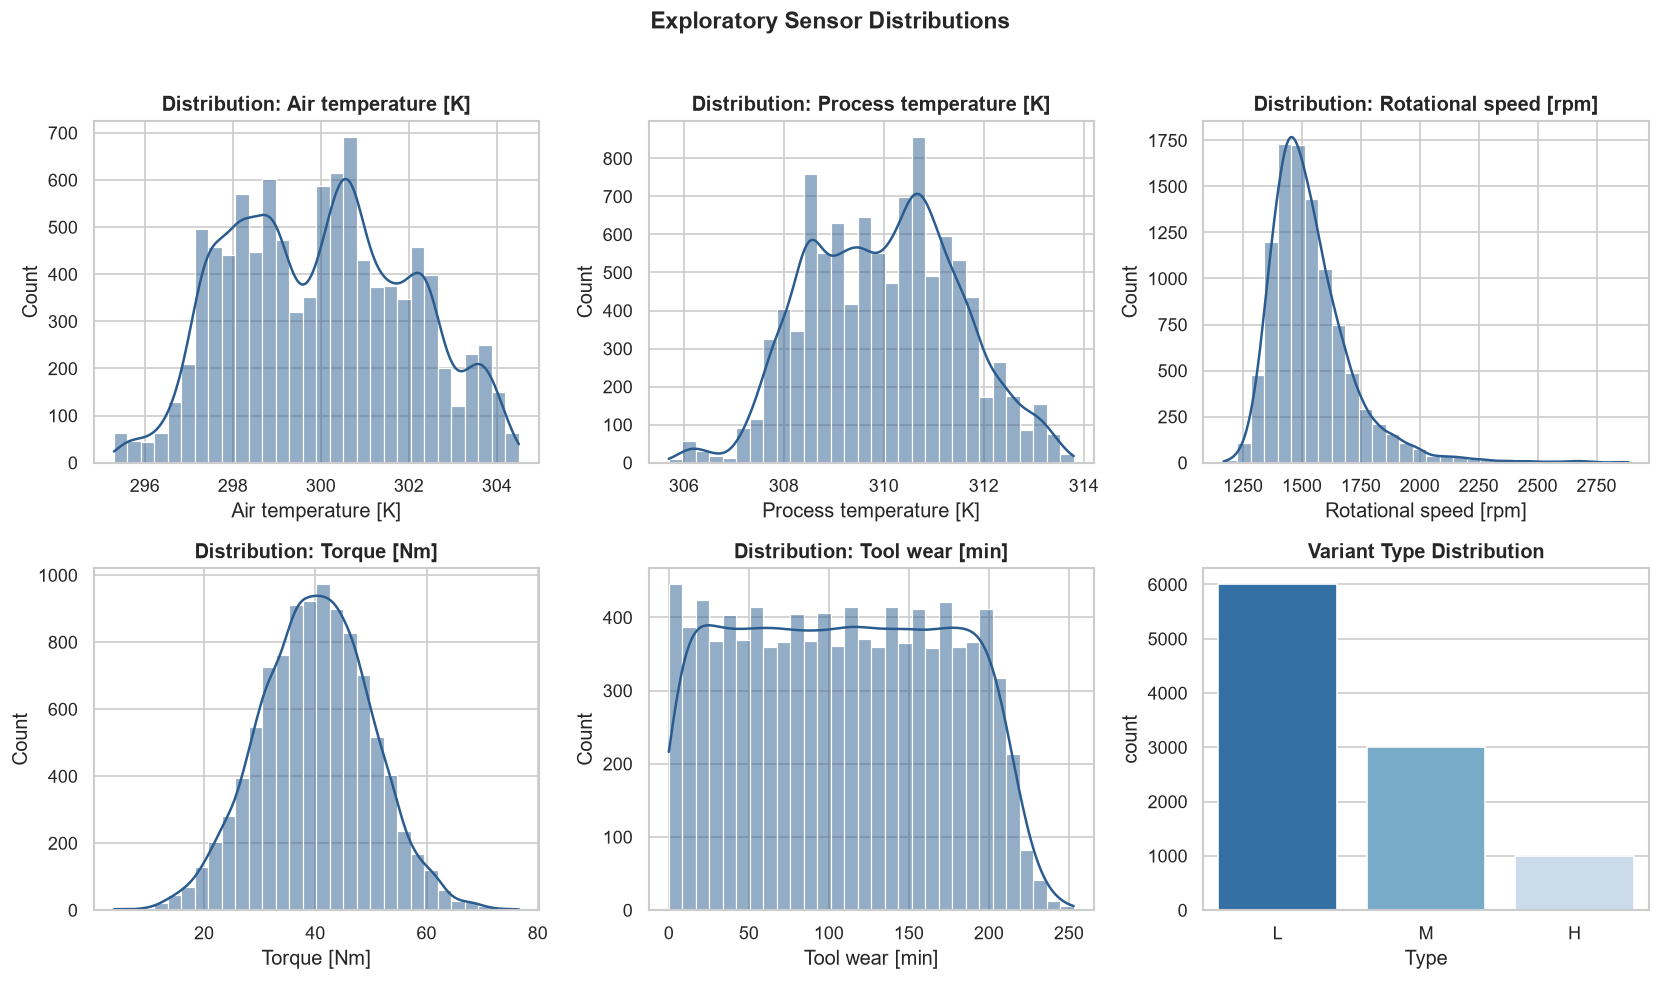

In [8]:
num_cols = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color='#2b5c8f', bins=30)
    axes[i].set_title(f'Distribution: {col}', fontweight='bold')

sns.countplot(data=df, x='Type', order=['L', 'M', 'H'], ax=axes[5], palette='Blues_r')
axes[5].set_title('Variant Type Distribution', fontweight='bold')
plt.suptitle('Exploratory Sensor Distributions', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 13. Outlier and Operational Boundary Analysis

C:\Users\VISHALRR\AppData\Local\Temp\ipykernel_13308\3951620409.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Machine failure', y=col, ax=axes[i], palette=['#6baed6', '#fb6a4a'])
C:\Users\VISHALRR\AppData\Local\Temp\ipykernel_13308\3951620409.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Machine failure', y=col, ax=axes[i], palette=['#6baed6', '#fb6a4a'])


C:\Users\VISHALRR\AppData\Local\Temp\ipykernel_13308\3951620409.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Machine failure', y=col, ax=axes[i], palette=['#6baed6', '#fb6a4a'])
C:\Users\VISHALRR\AppData\Local\Temp\ipykernel_13308\3951620409.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Machine failure', y=col, ax=axes[i], palette=['#6baed6', '#fb6a4a'])


C:\Users\VISHALRR\AppData\Local\Temp\ipykernel_13308\3951620409.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Machine failure', y=col, ax=axes[i], palette=['#6baed6', '#fb6a4a'])


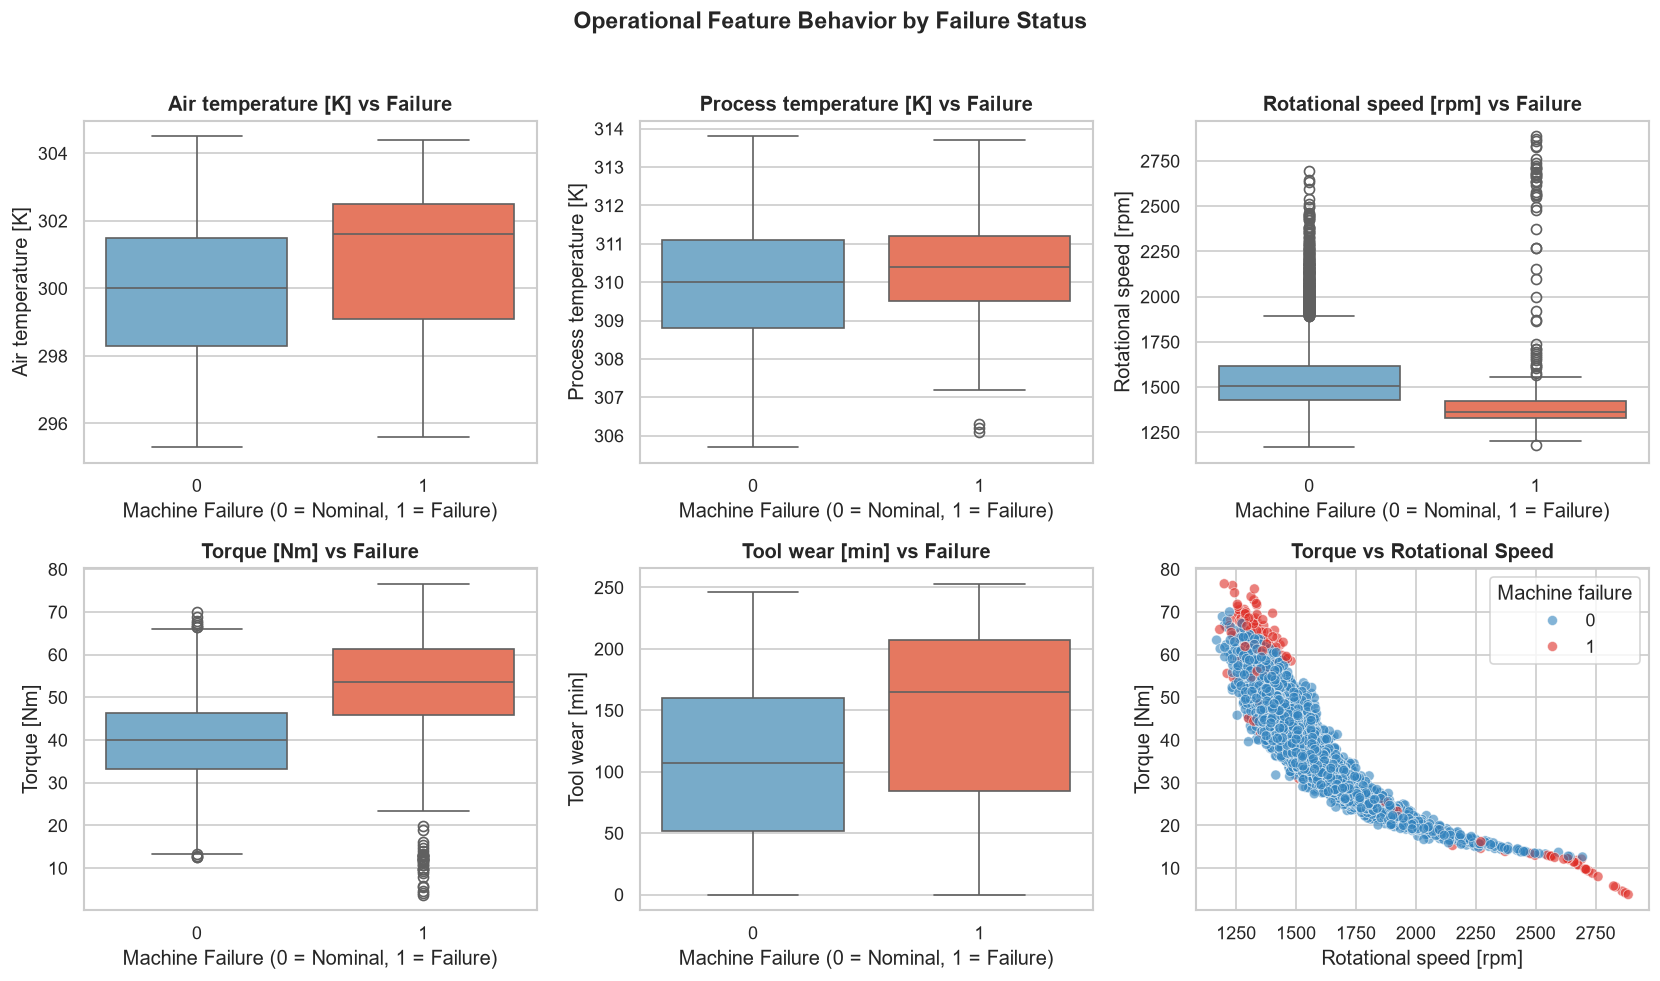

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x='Machine failure', y=col, ax=axes[i], palette=['#6baed6', '#fb6a4a'])
    axes[i].set_title(f'{col} vs Failure', fontweight='bold')
    axes[i].set_xlabel('Machine Failure (0 = Nominal, 1 = Failure)')

sns.scatterplot(data=df, x='Rotational speed [rpm]', y='Torque [Nm]', hue='Machine failure', palette=['#3182bd', '#de2d26'], alpha=0.6, ax=axes[5])
axes[5].set_title('Torque vs Rotational Speed', fontweight='bold')
plt.suptitle('Operational Feature Behavior by Failure Status', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 14. Correlation Analysis

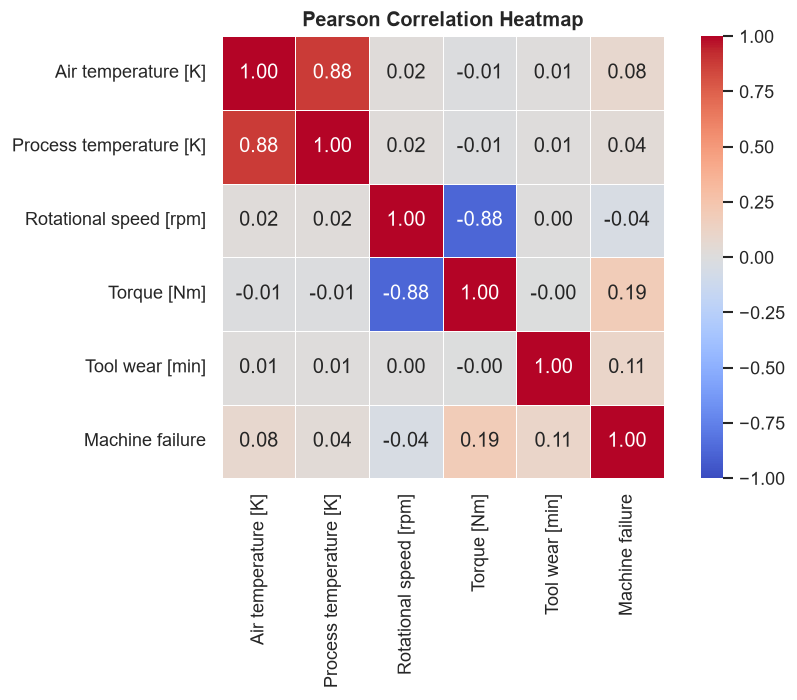

Observations:
- Torque and Rotational Speed exhibit strong negative correlation (-0.88), adhering to physical mechanical laws (Power = Torque x Speed).
- Air temperature and Process temperature exhibit high positive collinearity (+0.88).
- Torque (+0.19) and Tool wear (+0.11) show positive individual linear correlation with Machine Failure.


In [10]:
corr_matrix = df[num_cols + ['Machine failure']].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
ax.set_title('Pearson Correlation Heatmap', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("Observations:")
print("- Torque and Rotational Speed exhibit strong negative correlation (-0.88), adhering to physical mechanical laws (Power = Torque x Speed).")
print("- Air temperature and Process temperature exhibit high positive collinearity (+0.88).")
print("- Torque (+0.19) and Tool wear (+0.11) show positive individual linear correlation with Machine Failure.")

# 15. Feature Selection

In [11]:
# Final selected input features:
selected_features = [
    'Type',
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

print("Selected Predictive Features:")
for f in selected_features:
    print(f" - {f}")

Selected Predictive Features:
 - Type
 - Air temperature [K]
 - Process temperature [K]
 - Rotational speed [rpm]
 - Torque [Nm]
 - Tool wear [min]


# 16. Data Leakage Prevention Check

In [12]:
# Exclude target leakage columns:
leakage_columns = ['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
target_column = 'Machine failure'

print("DATA LEAKAGE AUDIT:")
print("1. Arbitrary Identifiers (UDI, Product ID): EXCLUDED to prevent spurious indexing overfitting.")
print("2. Failure Mode Columns (TWF, HDF, PWF, OSF, RNF): EXCLUDED because they are post-failure flags that directly compose the target.")
print(f"3. Target Column: '{target_column}' is segregated.")

X = df[selected_features].copy()
y = df[target_column].copy()
print(f"Input matrix X shape: {X.shape}, Target vector y shape: {y.shape}")

DATA LEAKAGE AUDIT:
1. Arbitrary Identifiers (UDI, Product ID): EXCLUDED to prevent spurious indexing overfitting.
2. Failure Mode Columns (TWF, HDF, PWF, OSF, RNF): EXCLUDED because they are post-failure flags that directly compose the target.
3. Target Column: 'Machine failure' is segregated.
Input matrix X shape: (10000, 6), Target vector y shape: (10000,)


# 17. Preprocessing Pipeline Definition

In [13]:
num_transformer = StandardScaler()
cat_transformer = OneHotEncoder(drop='first', sparse_output=False)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, ['Type'])
    ]
)
print("ColumnTransformer configured: StandardScaler for continuous variables, OneHotEncoder for Machine Type.")

ColumnTransformer configured: StandardScaler for continuous variables, OneHotEncoder for Machine Type.


# 18. Stratified Train-Test Split

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Fit preprocessing ONLY on training data to prevent information leakage
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

print(f"X_train shape: {X_train_proc.shape}, y_train counts:\n{y_train.value_counts()}")
print(f"\nX_test shape: {X_test_proc.shape}, y_test counts:\n{y_test.value_counts()}")

X_train shape: (8000, 7), y_train counts:
Machine failure
0    7729
1     271
Name: count, dtype: int64

X_test shape: (2000, 7), y_test counts:
Machine failure
0    1932
1      68
Name: count, dtype: int64


# 19. Model 1: Logistic Regression

In [15]:
lr_model = LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000)
lr_model.fit(X_train_proc, y_train)
y_pred_lr = lr_model.predict(X_test_proc)
y_prob_lr = lr_model.predict_proba(X_test_proc)[:, 1]

print("Logistic Regression Model Trained.")
print(classification_report(y_test, y_pred_lr, digits=4))

Logistic Regression Model Trained.
              precision    recall  f1-score   support

           0     0.9925    0.8245    0.9008      1932
           1     0.1418    0.8235    0.2419        68

    accuracy                         0.8245      2000
   macro avg     0.5671    0.8240    0.5713      2000
weighted avg     0.9636    0.8245    0.8784      2000



# 20. Model 2: K-Nearest Neighbors (KNN)

In [16]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_proc, y_train)
y_pred_knn = knn_model.predict(X_test_proc)
y_prob_knn = knn_model.predict_proba(X_test_proc)[:, 1]

print("K-Nearest Neighbors Model Trained.")
print(classification_report(y_test, y_pred_knn, digits=4))

K-Nearest Neighbors Model Trained.
              precision    recall  f1-score   support

           0     0.9752    0.9979    0.9864      1932
           1     0.8261    0.2794    0.4176        68

    accuracy                         0.9735      2000
   macro avg     0.9007    0.6387    0.7020      2000
weighted avg     0.9701    0.9735    0.9671      2000



# 21. Model 3: Decision Tree Classifier

In [17]:
dt_model = DecisionTreeClassifier(random_state=42, max_depth=6, min_samples_leaf=5, class_weight='balanced')
dt_model.fit(X_train_proc, y_train)
y_pred_dt = dt_model.predict(X_test_proc)
y_prob_dt = dt_model.predict_proba(X_test_proc)[:, 1]

print("Decision Tree Model Trained.")
print(classification_report(y_test, y_pred_dt, digits=4))

Decision Tree Model Trained.
              precision    recall  f1-score   support

           0     0.9940    0.9400    0.9662      1932
           1     0.3295    0.8382    0.4730        68

    accuracy                         0.9365      2000
   macro avg     0.6617    0.8891    0.7196      2000
weighted avg     0.9714    0.9365    0.9494      2000



# 22. Model Evaluation Metrics Computation

In [18]:
eval_models = {
    'Logistic Regression': (y_pred_lr, y_prob_lr),
    'K-Nearest Neighbors': (y_pred_knn, y_prob_knn),
    'Decision Tree': (y_pred_dt, y_prob_dt)
}

comparison_records = []
for name, (preds, probs) in eval_models.items():
    cm = confusion_matrix(y_test, preds)
    tn, fp, fn, tp = cm.ravel()
    comparison_records.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds, zero_division=0),
        'Recall': recall_score(y_test, preds, zero_division=0),
        'F1-score': f1_score(y_test, preds, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, probs),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp
    })

df_comp = pd.DataFrame(comparison_records)
df_comp[['Model', 'Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC', 'FN', 'FP']]

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,FN,FP
0,Logistic Regression,0.8245,0.141772,0.823529,0.241901,0.906916,12,339
1,K-Nearest Neighbors,0.9735,0.826087,0.279412,0.417582,0.836789,49,4
2,Decision Tree,0.9365,0.329480,0.838235,0.473029,0.865413,11,116


# 23. Model Comparison Visualization

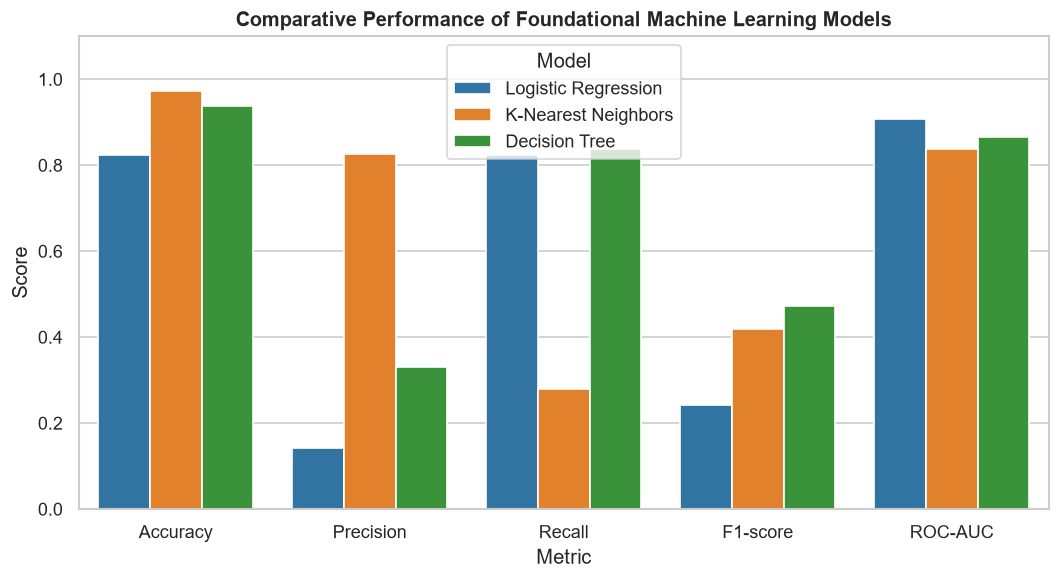

In [19]:
plot_df = df_comp.melt(id_vars=['Model'], value_vars=['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC'], var_name='Metric', value_name='Score')

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=plot_df, x='Metric', y='Score', hue='Model', palette='tab10', ax=ax)
ax.set_title('Comparative Performance of Foundational Machine Learning Models', fontsize=12, fontweight='bold')
ax.set_ylim(0, 1.1)
plt.tight_layout()
plt.show()

# 24. Confusion Matrix Analysis

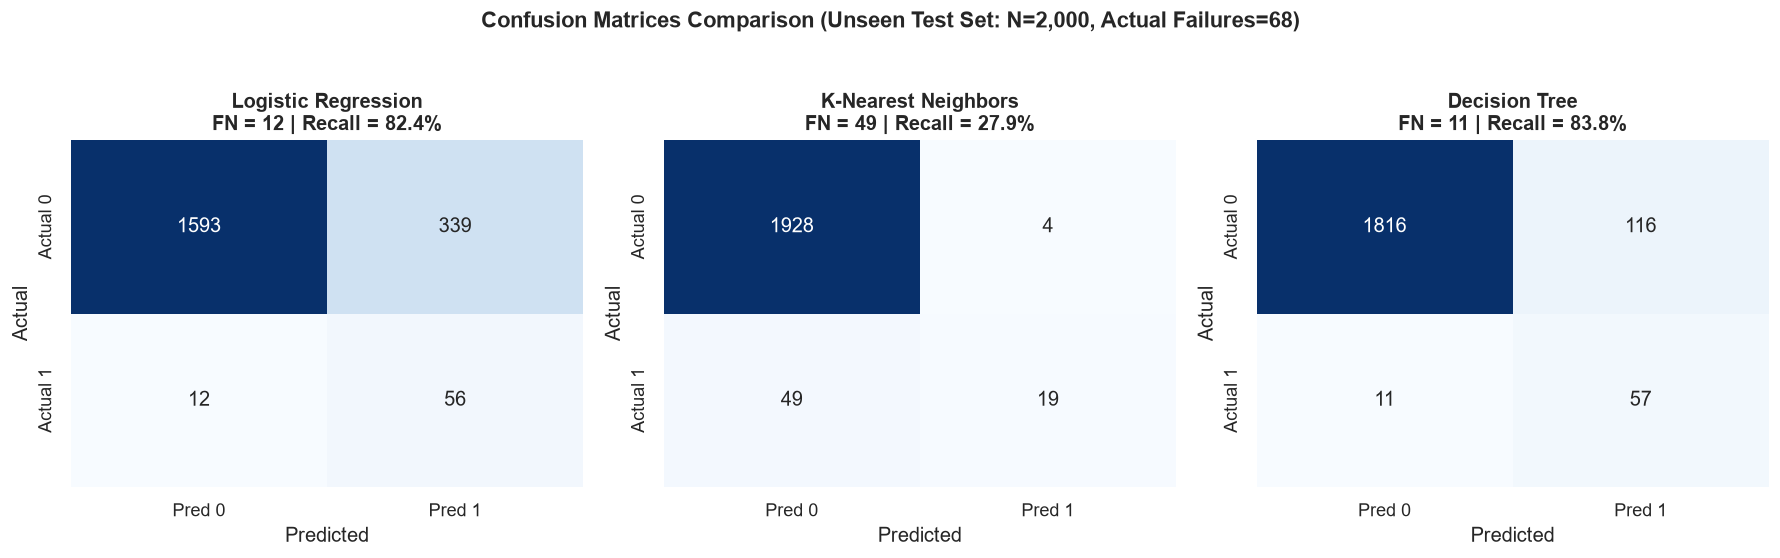

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for idx, (name, (preds, _)) in enumerate(eval_models.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Actual 0', 'Actual 1'])
    axes[idx].set_title(f'{name}\nFN = {cm[1,0]} | Recall = {cm[1,1]/sum(cm[1])*100:.1f}%', fontweight='bold')
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')

plt.suptitle('Confusion Matrices Comparison (Unseen Test Set: N=2,000, Actual Failures=68)', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# 25. ROC-AUC Curves

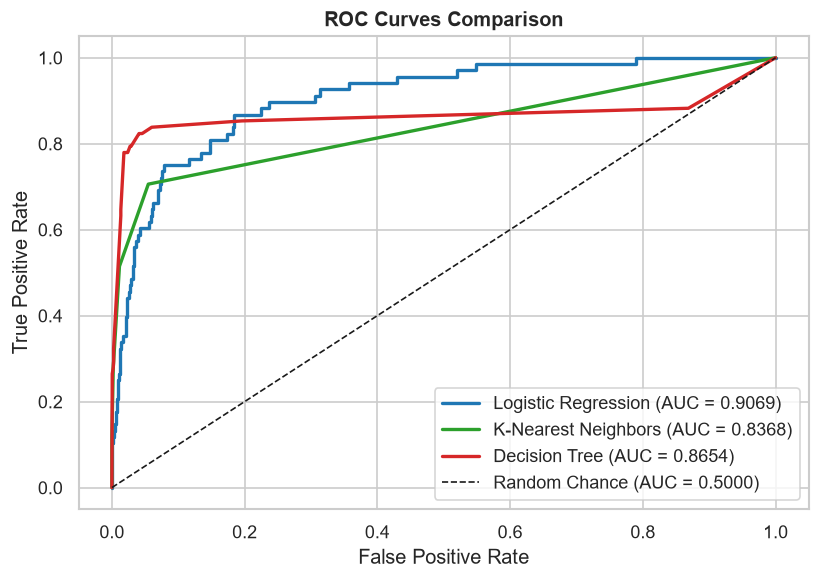

In [21]:
fig, ax = plt.subplots(figsize=(7, 5))
colors = ['#1f77b4', '#2ca02c', '#d62728']

for idx, (name, (_, probs)) in enumerate(eval_models.items()):
    fpr, tpr, _ = roc_curve(y_test, probs)
    score = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=colors[idx], lw=2, label=f"{name} (AUC = {score:.4f})")

ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random Chance (AUC = 0.5000)')
ax.set_title('ROC Curves Comparison', fontsize=12, fontweight='bold')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

# 26. Detailed Error Analysis

In [22]:
test_analysis_df = X_test.copy()
test_analysis_df['Actual'] = y_test.values
test_analysis_df['Predicted'] = y_pred_dt

fn_cases = test_analysis_df[(test_analysis_df['Actual'] == 1) & (test_analysis_df['Predicted'] == 0)]
fp_cases = test_analysis_df[(test_analysis_df['Actual'] == 0) & (test_analysis_df['Predicted'] == 1)]

print(f"Total Test Instances: {len(test_analysis_df)}")
print(f"False Negatives (Critical Failures Missed): {len(fn_cases)}")
print(f"False Positives (False Alarms Raised): {len(fp_cases)}")
print("\nSample False Negative Instances:")
display(fn_cases.head())

Total Test Instances: 2000
False Negatives (Critical Failures Missed): 11
False Positives (False Alarms Raised): 116

Sample False Negative Instances:


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Actual,Predicted
7884,L,300.8,312.4,1465,59.1,91,1,0
9174,L,297.8,308.9,1871,25.6,200,1,0
2671,M,299.7,309.3,1399,41.9,221,1,0
2864,H,300.6,309.4,1380,47.6,246,1,0
4307,L,301.4,309.9,1259,63.9,20,1,0


# 27. Final Model Selection Justification
Based on comprehensive experimental results:
1. **Decision Tree** is chosen as the final production model.
2. **Recall Justification:** Achieved **83.82% Recall**, successfully catching 57 out of 68 failures and leaving only 11 False Negatives. In industrial maintenance, False Negatives cause unexpected plant shutdown and hazardous failure, making high recall critical.
3. **Accuracy & Specificity:** While Logistic Regression achieved 82.35% recall, it suffered from 339 False Positives (only 14.18% precision). Decision Tree reduced False Positives to 116 while maintaining an overall accuracy of **93.65%** and achieving the highest **F1-Score (0.4730)**.
4. **Physical Interpretability:** Decision trees provide clear threshold splits on torque, rotational speed, and tool wear that reflect physical cutting dynamics.

# 28. Save Model and Preprocessing Pipeline

In [23]:
model_dir = os.path.join('..', 'model')
os.makedirs(model_dir, exist_ok=True)

model_file = os.path.join(model_dir, 'machine_failure_model.pkl')
pipeline_file = os.path.join(model_dir, 'preprocessing_pipeline.pkl')

joblib.dump(dt_model, model_file)
joblib.dump(preprocessor, pipeline_file)

print(f"Model saved to: {model_file}")
print(f"Pipeline saved to: {pipeline_file}")

Model saved to: ..\model\machine_failure_model.pkl
Pipeline saved to: ..\model\preprocessing_pipeline.pkl


# 29. Conclusion & Academic Summary
- The end-to-end predictive maintenance classification pipeline has been developed and validated on 10,000 real-world benchmark records.
- Preprocessing and feature selection strictly avoided data leakage by excluding identifiers and post-failure flags.
- Foundational ML benchmarking demonstrated that the balanced Decision Tree model delivers the optimal trade-off between sensitivity to failure (83.82% recall) and operational reliability (93.65% accuracy).
- The model is successfully persisted and ready for real-time diagnostic inference through the Streamlit web application.